# DATA 266 - Homework 7: GANs, FC-AE, and VAE

- FashionMNIST instead of MNIST.
- Latent size 32 for both models (the demo built the VAE with 32 but labeled it latent_dim=2).
- Both losses are reported per image (BCE summed over the 784 pixels), so the two models can be compared directly. The demo used a per-pixel mean for the AE and a per-batch sum for the VAE.
- Batch size 256 is actually passed to the training loop (the demo's train_autoencoder ignored it), and the loop adds loss.item() instead of the loss tensor.
- 20 epochs for both models, plus a final evaluation on the test set.

## Step 0: Personal Parameters

Same formulas as Assignment 1. The cell checks that the values match the ones I have used all semester.

- **SEED** seeds Python, NumPy, and PyTorch, the train/validation split, DataLoader shuffling, the VAE noise, and the prior samples.
- **SLICE** picks the display images: the first test image of each class at index 486 or later.
- **HP_ID** = 0. The assignment says a second hyperparameter configuration can be skipped because we already train two different models, so each model uses one configuration.
- **CLS_A and CLS_B** are only reported. Nothing in this assignment uses them.

In [1]:
SID4 = 9486
SEED = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10

assert (SEED, SLICE, HP_ID, CLS_A, CLS_B) == (9486, 486, 0, 6, 0)

print(f"SID4  = {SID4}")
print(f"SEED  = {SEED}")
print(f"SLICE = {SLICE}")
print(f"HP_ID = {HP_ID}")
print(f"CLS_A = {CLS_A}")
print(f"CLS_B = {CLS_B}")

SID4  = 9486
SEED  = 9486
SLICE = 486
HP_ID = 0
CLS_A = 6
CLS_B = 0


### Imports and Reproducibility Setup

- set_seed seeds random, NumPy, and PyTorch, and I call it again before each model and each random step.
- torch.use_deterministic_algorithms(True) (plus CUBLAS_WORKSPACE_CONFIG for GPUs) forces deterministic kernels.
- Each DataLoader gets its own seeded torch.Generator, so the shuffling order is the same on every run.
- log() prints each line with a UTC timestamp and also saves it to results/run_log_raw.txt (used for RUN_LOG.txt). All paths are relative.

In [2]:
import os
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")  # needed for deterministic cuBLAS on GPU

import json
import random
import time
import warnings
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
import torchvision
from torch import nn, optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets
from torchvision.transforms import v2 as T
from torchvision.utils import make_grid

for folder in ["figures", "results", "checkpoints"]:
    os.makedirs(folder, exist_ok=True)

LOG_PATH = "results/run_log_raw.txt"
open(LOG_PATH, "w").close()  # start a fresh log for this run


def log(*args):
    stamp = datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")
    line = f"[{stamp}] " + " ".join(str(a) for a in args)
    print(line)
    with open(LOG_PATH, "a") as f:
        f.write(line + "\n")


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def make_generator(seed=SEED):
    g = torch.Generator()
    g.manual_seed(seed)
    return g


torch.use_deterministic_algorithms(True)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
set_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
log("device:", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else "CPU only")
log("torch", torch.__version__, "| torchvision", torchvision.__version__, "| numpy", np.__version__)

[2026-10-20T05:24:04Z] device: cpu | CPU only
[2026-10-20T05:24:04Z] torch 2.14.1 | torchvision 0.29.1 | numpy 2.5.4


# Question 1: GAN Architecture

A GAN has two neural networks that are trained against each other.

- **Generator (G):** takes a random noise vector z (for example 100 values from N(0, I)) and turns it into a fake image G(z). In Demo_7_GAN it is an MLP, 100 → 256 → 512 → 1024 → 784, with tanh at the output. G never sees real images. It only learns from the discriminator's feedback.
- **Discriminator (D):** a binary classifier that outputs how likely an image is to be real. In the demo it is 784 → 512 → 256 → 1 with LeakyReLU(0.2), trained with BCEWithLogitsLoss.

**How they interact during training.** The two networks take turns on every batch:

1. **Update D:** real images get label 1 and fake images G(z) get label 0. The fakes are detached, so G is not updated in this step.
2. **Update G:** make new fakes, pass them through D, and compute the loss as if they were real (label 1). The gradient flows back through D into G, so G learns to make images that D thinks are real.

A simple way to think about it: G is a counterfeiter and D is a detective. As one gets better, the other is forced to improve too.

**Objective.** The original GAN paper (Goodfellow et al., 2014) writes this as a minimax game:

$$
\min_G \max_D \; V(D, G) = \mathbb{E}_{x \sim p_{data}}\big[\log D(x)\big] + \mathbb{E}_{z \sim p_z}\big[\log\big(1 - D(G(z))\big)\big]
$$

D wants to maximize V (score real images close to 1 and fakes close to 0), while G wants to minimize it (make D(G(z)) close to 1). In practice G maximizes log D(G(z)) instead (the "non-saturating" loss), because early in training D(G(z)) ≈ 0 and log(1 − D(G(z))) gives almost no gradient. The demo does this with criterion(D(fake), real_labels).

**Theoretical goal.** For a fixed G, the best discriminator is D*(x) = p_data(x) / (p_data(x) + p_g(x)). Plugging that back in gives V = −log 4 + 2·JSD(p_data ‖ p_g), which is smallest only when p_g = p_data. So the goal is for the generator to learn the real data distribution exactly. At that point D(x) = 1/2 everywhere, meaning D can no longer tell real from fake. In practice this equilibrium is hard to reach, which leads to problems like mode collapse.

# Question 2: Mode Collapse

**What it is.** Mode collapse is when the generator only produces a few kinds of outputs instead of the full variety in the data. On FashionMNIST, for example, a collapsed GAN might only make sneakers, or the same few T-shirts, no matter which z it gets.

**Why it happens.** G is only rewarded for fooling the current D, not for being diverse. If one type of output fools D well, G pushes many different z values toward it. D then learns to reject that output, G jumps to another one, and the two keep chasing each other instead of converging. D also judges each image on its own, so it cannot easily notice that a whole batch of fakes looks the same.

**Two ways to reduce it:**

1. **Minibatch discrimination / minibatch standard deviation.** D is given features computed across the whole batch, such as how similar the samples are to each other (Salimans et al., 2016), or the average standard deviation of the features (used in ProGAN and StyleGAN). A collapsed batch has very little variation, so D can spot it easily. That gives G a direct gradient toward producing more diverse outputs.
2. **WGAN-GP.** D is replaced by a "critic" that estimates the Wasserstein distance between the real and fake distributions (Arjovsky et al., 2017). A gradient penalty keeps the critic 1-Lipschitz (Gulrajani et al., 2017). With the original loss (JS divergence), G gets almost no useful gradient when the two distributions barely overlap. The Wasserstein distance still changes smoothly in that case, so training is more stable, and G keeps getting pushed toward covering the whole distribution instead of sticking to one mode.

Other common tricks include spectral normalization, one-sided label smoothing, and unrolled GANs.

# Question 3: Three GAN Variants

### DCGAN (Radford et al., 2015)

- **Problem:** fully connected GANs like the one in the demo ignore the 2D structure of images and were very unstable. Simply swapping in CNNs did not train reliably at first either.
- **Changes:** strided convolutions in D and transposed convolutions in G instead of pooling, BatchNorm in both networks, no fully connected hidden layers, ReLU in G (tanh at the output) and LeakyReLU in D, and Adam with lr = 2e-4 and β1 = 0.5.
- **Why it helps:** convolutions learn local patterns like edges and textures with far fewer parameters, and BatchNorm and LeakyReLU keep the gradients stable. The demo already uses DCGAN's Adam settings and activations, just with fully connected layers.

### StyleGAN (Karras et al., 2019)

- **Problem:** in a normal generator, z goes straight into the first layer, so attributes like pose, color, and texture all get mixed together and are hard to control separately.
- **Changes:** a mapping network (an 8-layer MLP) turns z into a latent vector w. The generator starts from a learned constant, and w is injected at every layer through AdaIN (adaptive instance normalization). Per-pixel noise adds random fine details, and style mixing is used during training.
- **Why it helps:** w is more disentangled than z, and injecting it layer by layer separates coarse features (pose and shape at low resolution) from fine ones (color and texture at high resolution). This gives high-quality images with much better control over what they look like.

### Conditional GAN (Mirza and Osindero, 2014)

- **Problem:** a vanilla GAN cannot choose what it generates. With the demo's GAN, you cannot ask for a sneaker specifically.
- **Changes:** both G and D get extra information y, usually a class label (as a one-hot vector or an embedding) concatenated to their input. The objective becomes the same minimax game with D(x | y) and G(z | y).
- **Why it helps:** G learns p(x | y), so you can choose the class when generating. D checks both that the image looks real and that it matches its label. The labels also give D and G an extra signal, which usually makes training more stable and helps G cover all the classes.

# Question 4: FC-AE and VAE on FashionMNIST

## 4.1 Dataset Loading and Preprocessing

FashionMNIST has 60,000 training and 10,000 test grayscale 28×28 images of clothing in 10 classes. I use the demo's transform:

1. T.ToImage() turns the image into a [1, 28, 28] tensor.
2. T.ToDtype(torch.float32, scale=True) scales the pixels to [0, 1]. This is needed because both decoders end with a sigmoid and the loss is BCE.
3. torch.flatten turns the image into a 784-dimensional vector, since both models are fully connected.

Like the demo, I split the training images 90/10 (seeded) into 54,000 for training and 6,000 for validation. The 10,000 test images are kept for the final evaluation and the figures.

In [3]:
transformation = T.Compose([
    T.ToImage(),
    T.ToDtype(torch.float32, scale=True),  # pixels to [0, 1]
    torch.flatten,                         # [1, 28, 28] -> [784]
])

t0 = time.time()
full_train_dataset = datasets.FashionMNIST(root="data", train=True, download=True, transform=transformation)
test_dataset = datasets.FashionMNIST(root="data", train=False, download=True, transform=transformation)
train_dataset, val_dataset = random_split(full_train_dataset, [0.9, 0.1], generator=make_generator(SEED))
log(f"FashionMNIST ready in {time.time() - t0:.1f}s | train {len(train_dataset)} | val {len(val_dataset)} | test {len(test_dataset)}")

class_names = full_train_dataset.classes
log("classes:", class_names)

[2026-10-20T05:24:05Z] FashionMNIST ready in 0.1s | train 54000 | val 6000 | test 10000
[2026-10-20T05:24:05Z] classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


## 4.2 Tensor Shapes

- one image: [784], float32, in [0, 1]
- one batch: images [256, 784], labels [256]
- inside both models: [B, 784] → [B, 256] → [B, 32] (latent) → [B, 256] → [B, 784]
- the VAE encoder outputs two [B, 32] tensors (mu and logvar)

The labels are not used for training (both models are unsupervised). I only use them to pick and caption the display images.

In [4]:
x0, y0 = test_dataset[0]
log(f"one image: shape {tuple(x0.shape)}, dtype {x0.dtype}, min {x0.min().item():.3f}, max {x0.max().item():.3f}, label {y0} ({class_names[y0]})")

xb, yb = next(iter(DataLoader(train_dataset, batch_size=256, shuffle=True, generator=make_generator(SEED))))
log(f"one batch: images {tuple(xb.shape)}, labels {tuple(yb.shape)}, pixel range [{xb.min().item():.3f}, {xb.max().item():.3f}]")

assert x0.shape == (784,) and x0.dtype == torch.float32
assert xb.shape == (256, 784) and xb.min() >= 0 and xb.max() <= 1
print("Shapes and pixel range look correct.")

[2026-10-20T05:24:05Z] one image: shape (784,), dtype torch.float32, min 0.000, max 1.000, label 9 (Ankle boot)
[2026-10-20T05:24:05Z] one batch: images (256, 784), labels (256,), pixel range [0.000, 1.000]
Shapes and pixel range look correct.


## 4.3 Dataset Inspection

The class counts in the training split should be close to balanced. I also pick the 10 test images used in every reconstruction figure: the first test image of each class at index SLICE (486) or later. Using the same images everywhere makes the FC-AE and VAE figures easy to compare.

[2026-10-20T05:24:05Z] training-split images per class: [5407, 5389, 5411, 5385, 5444, 5406, 5390, 5393, 5375, 5400]
[2026-10-20T05:24:05Z] display test indices (one per class, starting at SLICE): [488, 487, 497, 490, 491, 502, 512, 494, 486, 493]


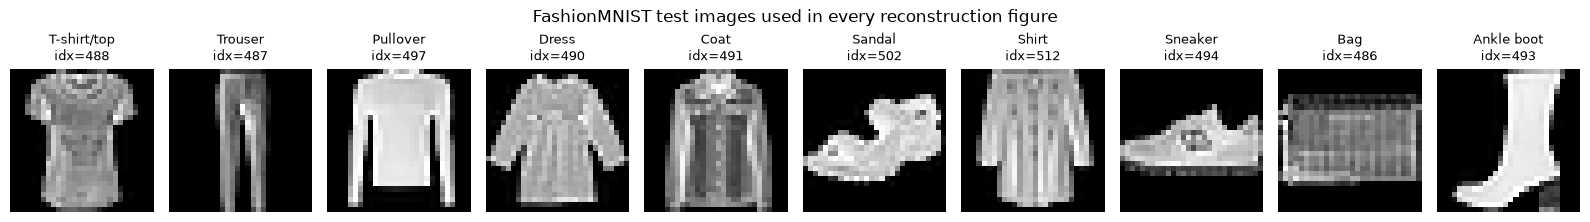

In [5]:
train_labels = full_train_dataset.targets[train_dataset.indices]
log("training-split images per class:", torch.bincount(train_labels, minlength=10).tolist())

test_labels = test_dataset.targets
DISPLAY_IDX = [next(i for i in range(SLICE, len(test_labels)) if int(test_labels[i]) == c) for c in range(10)]
log("display test indices (one per class, starting at SLICE):", DISPLAY_IDX)

x_display = torch.stack([test_dataset[i][0] for i in DISPLAY_IDX])  # [10, 784]
y_display = [class_names[int(test_labels[i])] for i in DISPLAY_IDX]
assert x_display.shape == (10, 784)

fig, axes = plt.subplots(1, 10, figsize=(16, 2.4))
for ax, img, name, idx in zip(axes, x_display, y_display, DISPLAY_IDX):
    ax.imshow(img.reshape(28, 28), cmap="gray")
    ax.set_title(f"{name}\nidx={idx}", fontsize=9)
    ax.axis("off")
plt.suptitle("FashionMNIST test images used in every reconstruction figure")
plt.tight_layout()
plt.savefig("figures/fashionmnist_display_images.png", dpi=150)
plt.show()

## 4.4 Settings Shared by Both Models

To keep the comparison fair, both models use the same hidden size (256), latent size (32), batch size (256), optimizer (Adam, lr = 1e-3), and number of epochs (20). These come from the demo, except that I used more epochs and a smaller batch size, so the models get more updates.

**Loss units.** Every loss is reported per image: BCE summed over the 784 pixels and averaged over the images. That way the FC-AE loss and the VAE's reconstruction term measure exactly the same thing. I also report the per-pixel MSE as a simpler second metric.

In [6]:
INPUT_DIM = 784
HIDDEN_DIM = 256
LATENT_DIM = 32
BATCH_SIZE = 256
LR = 1e-3
EPOCHS = 20

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, generator=make_generator(SEED))
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)
log(f"batches per epoch: train {len(train_loader)} | val {len(val_loader)} | test {len(test_loader)}")


def recon_bce_sum(x_recon, x):
    # binary cross entropy summed over pixels and images; divided by the image count later
    return F.binary_cross_entropy(x_recon, x, reduction="sum")


def kl_divergence_sum(mu, logvar):
    # KL( N(mu, sigma^2) || N(0, I) ) summed over latent dimensions and images
    return -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())


def count_params(model):
    return sum(p.numel() for p in model.parameters())


def show_reconstructions(original_flat, reconstructed_flat, n=10, title="Reconstruction", path=None):
    # Demo helper: originals on top, reconstructions below (plus class names and an optional save)
    plt.figure(figsize=(2 * n, 4.4))
    for i in range(n):
        ax = plt.subplot(2, n, i + 1)
        plt.imshow(original_flat.cpu()[i].reshape(28, 28), cmap="gray")
        plt.axis("off")
        ax.set_title(("Original\n" if i == 0 else "\n") + y_display[i], fontsize=9)
        ax = plt.subplot(2, n, i + 1 + n)
        plt.imshow(reconstructed_flat.cpu().detach()[i].reshape(28, 28), cmap="gray")
        plt.axis("off")
        if i == 0:
            ax.set_title("Reconstructed", fontsize=9)
    plt.suptitle(title)
    plt.tight_layout()
    if path:
        plt.savefig(path, dpi=150)
    plt.show()


run_times = {}

[2026-10-20T05:24:05Z] batches per epoch: train 211 | val 24 | test 40


## 4.5 FC-AE Architecture and Loss

| Part | Layer | Output shape | Activation |
| --- | --- | --- | --- |
| Input | flattened image | [B, 784] | none |
| Encoder | Linear(784, 256) | [B, 256] | ReLU |
| Encoder | Linear(256, 32) | [B, 32] (latent z) | none |
| Decoder | Linear(32, 256) | [B, 256] | ReLU |
| Decoder | Linear(256, 784) | [B, 784] | Sigmoid |

The encoder compresses 784 pixels into 32 numbers, and the decoder has to rebuild the image from only those. The sigmoid keeps the output pixels in (0, 1), the same range as the input.

**Loss: binary cross entropy (BCE).** Since the pixels are in [0, 1] and the output is a sigmoid, each output pixel can be treated as a probability, so BCE is a natural reconstruction loss. It is also the same reconstruction term the VAE uses. FashionMNIST pixels are not exactly 0 or 1, so the BCE can never reach 0.

In [7]:
class Encoder(nn.Module):
    def __init__(self, latent_dim=32):
        super().__init__()
        self.linear1 = nn.Linear(INPUT_DIM, HIDDEN_DIM)
        self.linear2 = nn.Linear(HIDDEN_DIM, latent_dim)

    def forward(self, x):
        x = torch.relu(self.linear1(x))
        return self.linear2(x)


class Decoder(nn.Module):
    def __init__(self, latent_dim=32):
        super().__init__()
        self.linear1 = nn.Linear(latent_dim, HIDDEN_DIM)
        self.linear2 = nn.Linear(HIDDEN_DIM, INPUT_DIM)

    def forward(self, z):
        z = torch.relu(self.linear1(z))
        return torch.sigmoid(self.linear2(z))


class AutoEncoder(nn.Module):
    def __init__(self, latent_dim=32):
        super().__init__()
        self.encoder = Encoder(latent_dim)
        self.decoder = Decoder(latent_dim)

    def forward(self, x):
        return self.decoder(self.encoder(x))


set_seed(SEED)
ae = AutoEncoder(LATENT_DIM).to(device)
print(ae)
log(f"FC-AE parameters: {count_params(ae):,}")

with torch.no_grad():
    z_check = ae.encoder(xb[:4].to(device))
    out_check = ae.decoder(z_check)
log(f"FC-AE shape check: input {tuple(xb[:4].shape)} -> latent {tuple(z_check.shape)} -> output {tuple(out_check.shape)}, "
    f"output range [{out_check.min().item():.3f}, {out_check.max().item():.3f}]")
assert z_check.shape == (4, LATENT_DIM) and out_check.shape == (4, INPUT_DIM)

AutoEncoder(
  (encoder): Encoder(
    (linear1): Linear(in_features=784, out_features=256, bias=True)
    (linear2): Linear(in_features=256, out_features=32, bias=True)
  )
  (decoder): Decoder(
    (linear1): Linear(in_features=32, out_features=256, bias=True)
    (linear2): Linear(in_features=256, out_features=784, bias=True)
  )
)
[2026-10-20T05:24:05Z] FC-AE parameters: 419,120
[2026-10-20T05:24:05Z] FC-AE shape check: input (4, 784) -> latent (4, 32) -> output (4, 784), output range [0.447, 0.550]


## 4.6 FC-AE Training

This is the demo's train_autoencoder loop with the fixes above (the batch size is actually used, loss.item() is used, and the losses are per image). The input and the target are the same image: x goes in, x̂ comes out, and the loss compares x̂ with x.

In [8]:
def train_autoencoder(model, train_loader, val_loader, epochs, lr, tag="FC-AE"):
    optimizer = optim.Adam(model.parameters(), lr=lr)
    history = {"train": [], "val": []}
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        model.train()
        total, n = 0.0, 0
        for x, _ in train_loader:
            x = x.to(device)
            optimizer.zero_grad()
            x_recon = model(x)
            loss_sum = recon_bce_sum(x_recon, x)
            (loss_sum / x.size(0)).backward()        # mean per image for the gradient step
            optimizer.step()
            total += loss_sum.item()
            n += x.size(0)
        train_loss = total / n

        model.eval()
        total, n = 0.0, 0
        with torch.no_grad():
            for x, _ in val_loader:
                x = x.to(device)
                total += recon_bce_sum(model(x), x).item()
                n += x.size(0)
        val_loss = total / n

        history["train"].append(train_loss)
        history["val"].append(val_loss)
        log(f"[{tag} epoch {epoch:02d}/{epochs}] train_bce {train_loss:.4f} | val_bce {val_loss:.4f} | {time.time() - t0:.1f}s")
    return history


set_seed(SEED)
t_start = time.time()
ae_history = train_autoencoder(ae, train_loader, val_loader, EPOCHS, LR)
run_times["fc_ae_training"] = time.time() - t_start
log(f"FC-AE training done in {run_times['fc_ae_training']:.1f}s")

[2026-10-20T05:24:11Z] [FC-AE epoch 01/20] train_bce 288.3456 | val_bce 242.6648 | 5.8s


[2026-10-20T05:24:17Z] [FC-AE epoch 02/20] train_bce 237.6771 | val_bce 232.5683 | 5.9s


[2026-10-20T05:24:23Z] [FC-AE epoch 03/20] train_bce 230.3193 | val_bce 227.6756 | 5.9s


[2026-10-20T05:24:29Z] [FC-AE epoch 04/20] train_bce 226.4207 | val_bce 224.6094 | 6.3s


[2026-10-20T05:24:36Z] [FC-AE epoch 05/20] train_bce 223.7972 | val_bce 222.3350 | 6.6s


...

[2026-10-20T05:25:37Z] [FC-AE epoch 16/20] train_bce 213.7046 | val_bce 213.3914 | 5.6s


[2026-10-20T05:25:42Z] [FC-AE epoch 17/20] train_bce 213.3002 | val_bce 213.0118 | 5.6s


[2026-10-20T05:25:48Z] [FC-AE epoch 18/20] train_bce 212.9864 | val_bce 212.6991 | 5.8s


[2026-10-20T05:25:54Z] [FC-AE epoch 19/20] train_bce 212.6860 | val_bce 212.5012 | 5.6s


[2026-10-20T05:25:59Z] [FC-AE epoch 20/20] train_bce 212.3813 | val_bce 212.2384 | 5.6s
[2026-10-20T05:25:59Z] FC-AE training done in 114.3s


## 4.7 FC-AE Evaluation and Visualizations

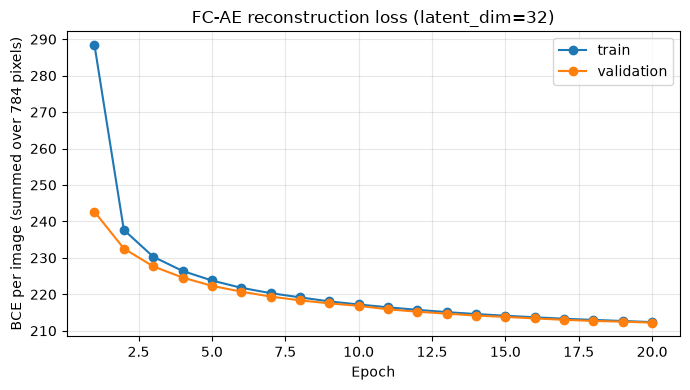

In [9]:
epochs_axis = range(1, EPOCHS + 1)
plt.figure(figsize=(7, 4))
plt.plot(epochs_axis, ae_history["train"], marker="o", label="train")
plt.plot(epochs_axis, ae_history["val"], marker="o", label="validation")
plt.title(f"FC-AE reconstruction loss (latent_dim={LATENT_DIM})")
plt.xlabel("Epoch")
plt.ylabel("BCE per image (summed over 784 pixels)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("figures/fc_ae_loss_curves.png", dpi=150)
plt.show()

For the test evaluation, I run all 10,000 test images through the trained FC-AE with no gradients, and compute the same per-image BCE plus the per-pixel MSE.

[2026-10-20T05:26:00Z] FC-AE test: BCE per image 214.1978 | MSE per pixel 0.009698


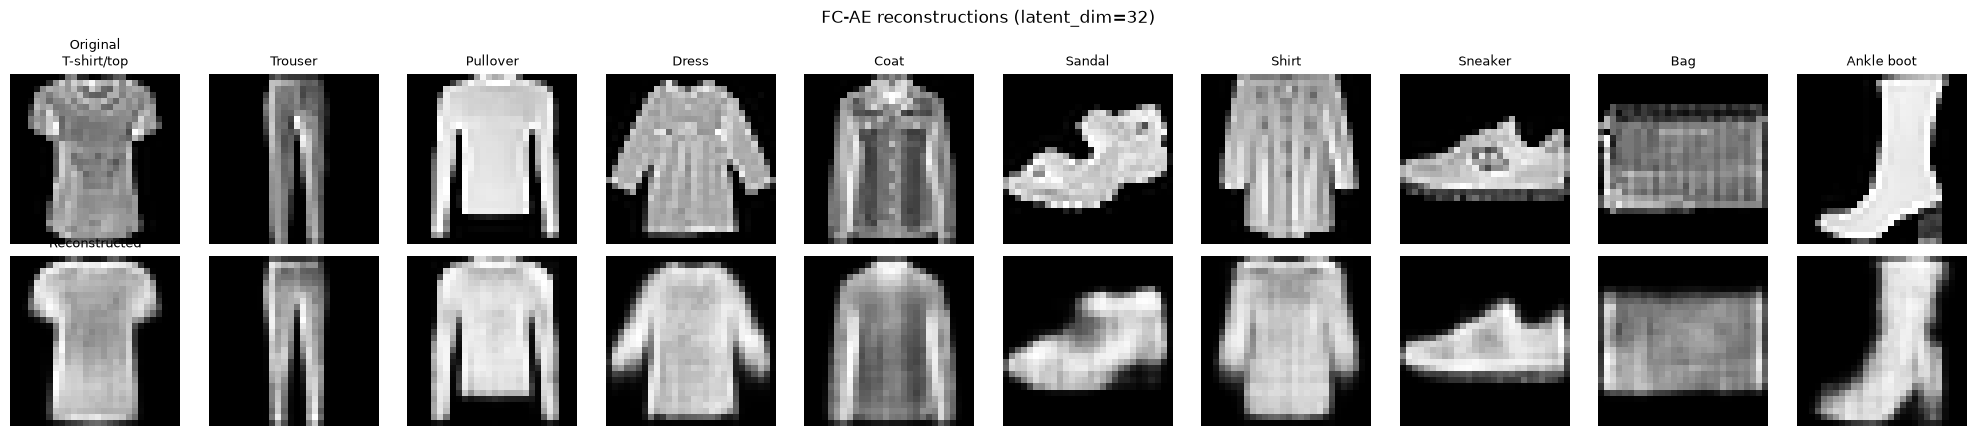

In [10]:
@torch.no_grad()
def evaluate_ae(model, loader):
    model.eval()
    bce_total, sq_total, n = 0.0, 0.0, 0
    for x, _ in loader:
        x = x.to(device)
        x_recon = model(x)
        bce_total += recon_bce_sum(x_recon, x).item()
        sq_total += F.mse_loss(x_recon, x, reduction="sum").item()
        n += x.size(0)
    return {"bce_per_image": bce_total / n, "mse_per_pixel": sq_total / (n * INPUT_DIM)}


ae_test = evaluate_ae(ae, test_loader)
log(f"FC-AE test: BCE per image {ae_test['bce_per_image']:.4f} | MSE per pixel {ae_test['mse_per_pixel']:.6f}")

with torch.no_grad():
    ae_display_recon = ae(x_display.to(device)).cpu()
show_reconstructions(x_display, ae_display_recon, title=f"FC-AE reconstructions (latent_dim={LATENT_DIM})",
                     path="figures/fc_ae_reconstructions.png")

## 4.8 VAE Architecture, Loss, and KL Term

The VAE uses the same layer sizes, but the encoder outputs a distribution for each image instead of a single point:

| Part | Layer | Output shape | Activation |
| --- | --- | --- | --- |
| Input | flattened image | [B, 784] | none |
| Encoder | Linear(784, 256) | [B, 256] | ReLU |
| Encoder head 1 | Linear(256, 32) → mu | [B, 32] | none |
| Encoder head 2 | Linear(256, 32) → logvar | [B, 32] | none |
| Sampling | z = mu + exp(0.5·logvar) · ε, ε ~ N(0, I) | [B, 32] | none |
| Decoder | Linear(32, 256) | [B, 256] | ReLU |
| Decoder | Linear(256, 784) | [B, 784] | Sigmoid |

**Reparameterization trick.** You cannot backpropagate through random sampling, so the randomness is moved into ε ~ N(0, I) and z is computed as mu + σ·ε. This makes z a differentiable function of mu and logvar, so the encoder can be trained. Predicting logvar instead of σ keeps σ = exp(0.5·logvar) always positive.

**Loss (negative ELBO):**

$$
\mathcal{L}(x) = \underbrace{\text{BCE}(\hat{x}, x)}_{\text{reconstruction}} + \underbrace{D_{KL}\big(q(z|x)\,\|\,\mathcal{N}(0, I)\big)}_{\text{KL term}}, \qquad
D_{KL} = -\tfrac{1}{2}\sum_{j=1}^{32}\big(1 + \log\sigma_j^2 - \mu_j^2 - \sigma_j^2\big)
$$

The reconstruction term is the same BCE as the FC-AE. The KL term measures how far each image's latent distribution is from the standard normal prior.

**Role of the KL term.** Without it, the VAE would act like a normal autoencoder: σ would shrink to 0 and the codes would spread out, leaving gaps in latent space. The KL term pulls mu toward 0 and σ toward 1, so the codes fill the region where N(0, I) has its probability. That is what makes generation possible, because a random z ~ N(0, I) lands somewhere the decoder has learned to decode. The cost is that the decoder gets noisier codes, so I expect the VAE's reconstructions to be blurrier than the FC-AE's.

In [11]:
class VEncoder(nn.Module):
    def __init__(self, latent_dim=32):
        super().__init__()
        self.linear1 = nn.Linear(INPUT_DIM, HIDDEN_DIM)
        self.linear_mu = nn.Linear(HIDDEN_DIM, latent_dim)
        self.linear_logvar = nn.Linear(HIDDEN_DIM, latent_dim)

    def forward(self, x):
        x = torch.relu(self.linear1(x))
        mu = self.linear_mu(x)
        logvar = self.linear_logvar(x)
        return mu, logvar


class VDecoder(nn.Module):
    def __init__(self, latent_dim=32):
        super().__init__()
        self.linear1 = nn.Linear(latent_dim, HIDDEN_DIM)
        self.linear2 = nn.Linear(HIDDEN_DIM, INPUT_DIM)

    def forward(self, z):
        z = torch.relu(self.linear1(z))
        return torch.sigmoid(self.linear2(z))


class VAE(nn.Module):
    def __init__(self, latent_dim=32):
        super().__init__()
        self.encoder = VEncoder(latent_dim)
        self.decoder = VDecoder(latent_dim)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        mu, logvar = self.encoder(x)
        z = self.reparameterize(mu, logvar)
        return self.decoder(z), mu, logvar


set_seed(SEED)
vae = VAE(LATENT_DIM).to(device)
print(vae)
log(f"VAE parameters: {count_params(vae):,}")

VAE(
  (encoder): VEncoder(
    (linear1): Linear(in_features=784, out_features=256, bias=True)
    (linear_mu): Linear(in_features=256, out_features=32, bias=True)
    (linear_logvar): Linear(in_features=256, out_features=32, bias=True)
  )
  (decoder): VDecoder(
    (linear1): Linear(in_features=32, out_features=256, bias=True)
    (linear2): Linear(in_features=256, out_features=784, bias=True)
  )
)
[2026-10-20T05:26:01Z] VAE parameters: 427,344


Quick checks before training:

- mu, logvar, and z are [B, 32], and the output is [B, 784].
- The KL of N(0, I) against the prior is 0, and with mu = 1 and logvar = 0 it should be 0.5 per dimension (16 in total).
- The total loss equals the reconstruction term plus the KL term.

In [12]:
with torch.no_grad():
    mu_c, logvar_c = vae.encoder(xb[:4].to(device))
    z_c = vae.reparameterize(mu_c, logvar_c)
    x_c, _, _ = vae(xb[:4].to(device))
log(f"VAE shape check: input {tuple(xb[:4].shape)} -> mu {tuple(mu_c.shape)}, logvar {tuple(logvar_c.shape)} -> "
    f"z {tuple(z_c.shape)} -> output {tuple(x_c.shape)}")
assert mu_c.shape == logvar_c.shape == z_c.shape == (4, LATENT_DIM) and x_c.shape == (4, INPUT_DIM)

zeros = torch.zeros(1, LATENT_DIM)
kl_prior = kl_divergence_sum(zeros, zeros).item()
kl_shift = kl_divergence_sum(torch.ones(1, LATENT_DIM), zeros).item()
log(f"KL check: KL(N(0,I) || N(0,I)) = {kl_prior:.4f} | KL(N(1,I) || N(0,I)) = {kl_shift:.4f} (expected 0 and 16)")
assert abs(kl_prior) < 1e-6 and abs(kl_shift - 16.0) < 1e-5

[2026-10-20T05:26:01Z] VAE shape check: input (4, 784) -> mu (4, 32), logvar (4, 32) -> z (4, 32) -> output (4, 784)
[2026-10-20T05:26:01Z] KL check: KL(N(0,I) || N(0,I)) = -0.0000 | KL(N(1,I) || N(0,I)) = 16.0000 (expected 0 and 16)


## 4.9 VAE Training

This is the demo's train_vae with the same fixes as the FC-AE loop. The reconstruction BCE, the KL, and the total are tracked separately for both train and validation. The validation loss also uses a sampled z, so it is the same quantity as the training loss.

In [13]:
def train_vae(model, train_loader, val_loader, epochs, lr, tag="VAE"):
    optimizer = optim.Adam(model.parameters(), lr=lr)
    history = {split: {"recon": [], "kl": [], "total": []} for split in ["train", "val"]}
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        for split, loader in [("train", train_loader), ("val", val_loader)]:
            training = split == "train"
            model.train(training)
            recon_total, kl_total, n = 0.0, 0.0, 0
            with torch.set_grad_enabled(training):
                for x, _ in loader:
                    x = x.to(device)
                    x_recon, mu, logvar = model(x)
                    recon = recon_bce_sum(x_recon, x)
                    kl = kl_divergence_sum(mu, logvar)
                    if training:
                        optimizer.zero_grad()
                        ((recon + kl) / x.size(0)).backward()
                        optimizer.step()
                    recon_total += recon.item()
                    kl_total += kl.item()
                    n += x.size(0)
            history[split]["recon"].append(recon_total / n)
            history[split]["kl"].append(kl_total / n)
            history[split]["total"].append((recon_total + kl_total) / n)
        tr, va = history["train"], history["val"]
        log(f"[{tag} epoch {epoch:02d}/{epochs}] train recon {tr['recon'][-1]:.4f} kl {tr['kl'][-1]:.4f} total {tr['total'][-1]:.4f} | "
            f"val recon {va['recon'][-1]:.4f} kl {va['kl'][-1]:.4f} total {va['total'][-1]:.4f} | {time.time() - t0:.1f}s")
    return history


set_seed(SEED)
t_start = time.time()
vae_history = train_vae(vae, train_loader, val_loader, EPOCHS, LR)
run_times["vae_training"] = time.time() - t_start
log(f"VAE training done in {run_times['vae_training']:.1f}s")

[2026-10-20T05:26:07Z] [VAE epoch 01/20] train recon 303.6442 kl 13.7414 total 317.3855 | val recon 260.2743 kl 16.0131 total 276.2874 | 5.8s


[2026-10-20T05:26:13Z] [VAE epoch 02/20] train recon 254.3556 kl 15.7891 total 270.1447 | val recon 249.1107 kl 15.4846 total 264.5953 | 5.8s


[2026-10-20T05:26:18Z] [VAE epoch 03/20] train recon 246.2070 kl 15.7525 total 261.9596 | val recon 243.8153 kl 15.3646 total 259.1799 | 5.7s


[2026-10-20T05:26:24Z] [VAE epoch 04/20] train recon 241.6102 kl 15.6752 total 257.2854 | val recon 239.3433 kl 15.4421 total 254.7854 | 5.8s


[2026-10-20T05:26:31Z] [VAE epoch 05/20] train recon 238.3587 kl 15.5421 total 253.9008 | val recon 236.8417 kl 15.4516 total 252.2934 | 6.7s


...

[2026-10-20T05:27:38Z] [VAE epoch 16/20] train recon 228.0418 kl 15.9540 total 243.9958 | val recon 227.4657 kl 16.1340 total 243.5997 | 5.8s


[2026-10-20T05:27:44Z] [VAE epoch 17/20] train recon 227.6777 kl 16.0036 total 243.6814 | val recon 227.0728 kl 16.2654 total 243.3382 | 6.3s


[2026-10-20T05:27:50Z] [VAE epoch 18/20] train recon 227.4462 kl 16.0299 total 243.4761 | val recon 227.2911 kl 15.8205 total 243.1116 | 6.2s


[2026-10-20T05:27:56Z] [VAE epoch 19/20] train recon 227.1761 kl 16.0593 total 243.2354 | val recon 226.6913 kl 16.1680 total 242.8593 | 5.8s


[2026-10-20T05:28:02Z] [VAE epoch 20/20] train recon 226.9387 kl 16.1034 total 243.0421 | val recon 226.4851 kl 16.5831 total 243.0682 | 5.8s
[2026-10-20T05:28:02Z] VAE training done in 120.7s


## 4.10 VAE Evaluation, Reconstructions, and Generated Samples

The three loss curves (reconstruction, KL, and total), laid out like the demo's figure:

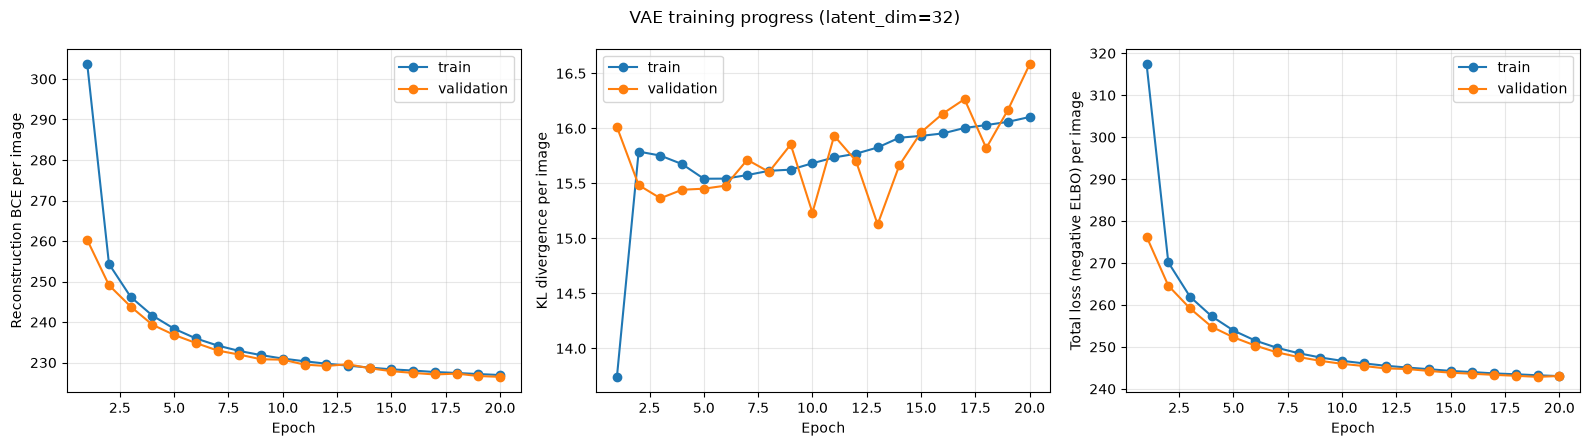

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, key, ylabel in zip(axes, ["recon", "kl", "total"],
                           ["Reconstruction BCE per image", "KL divergence per image", "Total loss (negative ELBO) per image"]):
    ax.plot(epochs_axis, vae_history["train"][key], marker="o", label="train")
    ax.plot(epochs_axis, vae_history["val"][key], marker="o", label="validation")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3)
    ax.legend()
fig.suptitle(f"VAE training progress (latent_dim={LATENT_DIM})")
plt.tight_layout()
plt.savefig("figures/vae_loss_curves.png", dpi=150)
plt.show()

On the test set I report:

1. **The VAE's own objective** (reconstruction BCE, KL, and total) with a sampled z, the same way as validation. The noise is seeded, so the result can be repeated.
2. **Reconstruction quality with z = mu** (no sampling noise). This is the fair comparison with the FC-AE, which is also deterministic. The reconstruction figure also uses z = mu.

[2026-10-20T05:28:03Z] VAE test (sampled z): recon BCE 228.3524 | KL 16.5931 | total 244.9455
[2026-10-20T05:28:03Z] VAE test (z = mu): BCE per image 223.7607 | MSE per pixel 0.013927


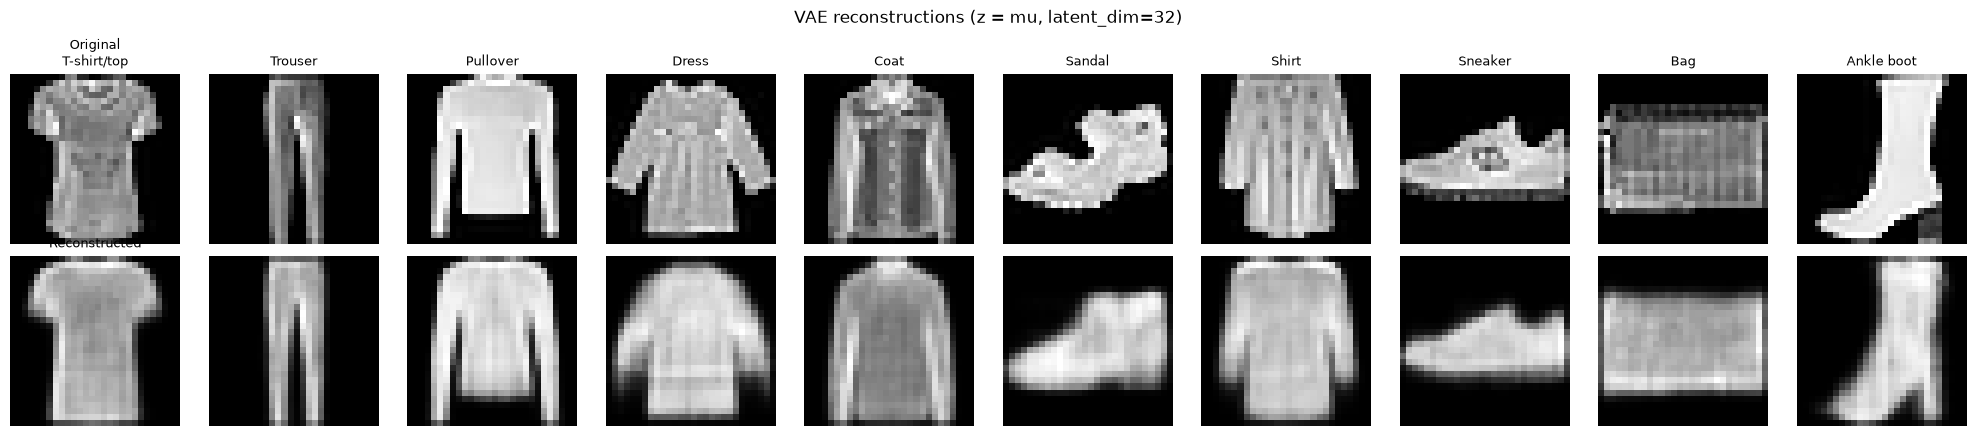

In [15]:
@torch.no_grad()
def evaluate_vae(model, loader):
    model.eval()
    recon_total, kl_total, recon_mu_total, sq_mu_total, n = 0.0, 0.0, 0.0, 0.0, 0
    for x, _ in loader:
        x = x.to(device)
        x_recon, mu, logvar = model(x)                       # sampled z (the training objective)
        recon_total += recon_bce_sum(x_recon, x).item()
        kl_total += kl_divergence_sum(mu, logvar).item()
        x_recon_mu = model.decoder(mu)                       # z = mu (deterministic reconstruction)
        recon_mu_total += recon_bce_sum(x_recon_mu, x).item()
        sq_mu_total += F.mse_loss(x_recon_mu, x, reduction="sum").item()
        n += x.size(0)
    return {"recon_bce_per_image": recon_total / n, "kl_per_image": kl_total / n,
            "total_per_image": (recon_total + kl_total) / n,
            "bce_per_image_mu": recon_mu_total / n, "mse_per_pixel_mu": sq_mu_total / (n * INPUT_DIM)}


set_seed(SEED)
vae_test = evaluate_vae(vae, test_loader)
log(f"VAE test (sampled z): recon BCE {vae_test['recon_bce_per_image']:.4f} | KL {vae_test['kl_per_image']:.4f} | "
    f"total {vae_test['total_per_image']:.4f}")
log(f"VAE test (z = mu): BCE per image {vae_test['bce_per_image_mu']:.4f} | MSE per pixel {vae_test['mse_per_pixel_mu']:.6f}")

with torch.no_grad():
    mu_display, _ = vae.encoder(x_display.to(device))
    vae_display_recon = vae.decoder(mu_display).cpu()
show_reconstructions(x_display, vae_display_recon, title=f"VAE reconstructions (z = mu, latent_dim={LATENT_DIM})",
                     path="figures/vae_reconstructions.png")

### Reconstruction vs. Generation

- **Reconstruction** starts from a real image: encode it, decode it, and check how close the output is to the input. Both models can do this.
- **Generation** has no input image. We sample a new z from N(0, I) and only run the decoder. The VAE can do this because the KL term trained its latent space to match N(0, I). The FC-AE's codes have no such constraint, so a random z might land somewhere its decoder never learned (the demo's section 7, "Why Vanilla AE is Not Generative").

Below are 64 images decoded from random z ~ N(0, I), drawn with a seeded generator.

[2026-10-20T05:28:04Z] Prior samples: z (64, 32) ~ N(0, I) -> images (64, 784)


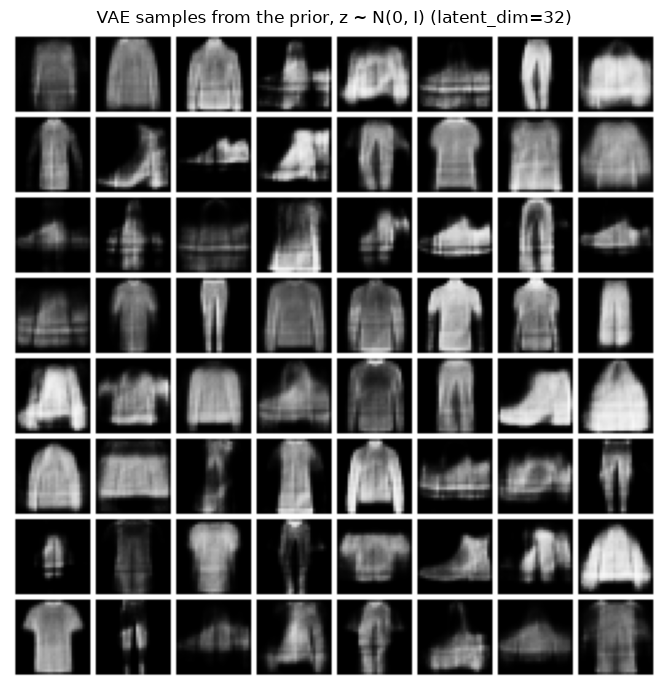

In [16]:
z_prior = torch.randn(64, LATENT_DIM, generator=make_generator(SEED)).to(device)
with torch.no_grad():
    vae_samples = vae.decoder(z_prior).cpu()
log(f"Prior samples: z {tuple(z_prior.shape)} ~ N(0, I) -> images {tuple(vae_samples.shape)}")

grid = make_grid(vae_samples.view(-1, 1, 28, 28), nrow=8, padding=2, pad_value=1.0)
plt.figure(figsize=(7, 7))
plt.imshow(grid.permute(1, 2, 0))
plt.axis("off")
plt.title("VAE samples from the prior, z ~ N(0, I) (latent_dim=32)")
plt.tight_layout()
plt.savefig("figures/vae_prior_samples.png", dpi=150)
plt.show()

## 4.11 Comparison of FC-AE and VAE

The same 10 test images reconstructed by both models:

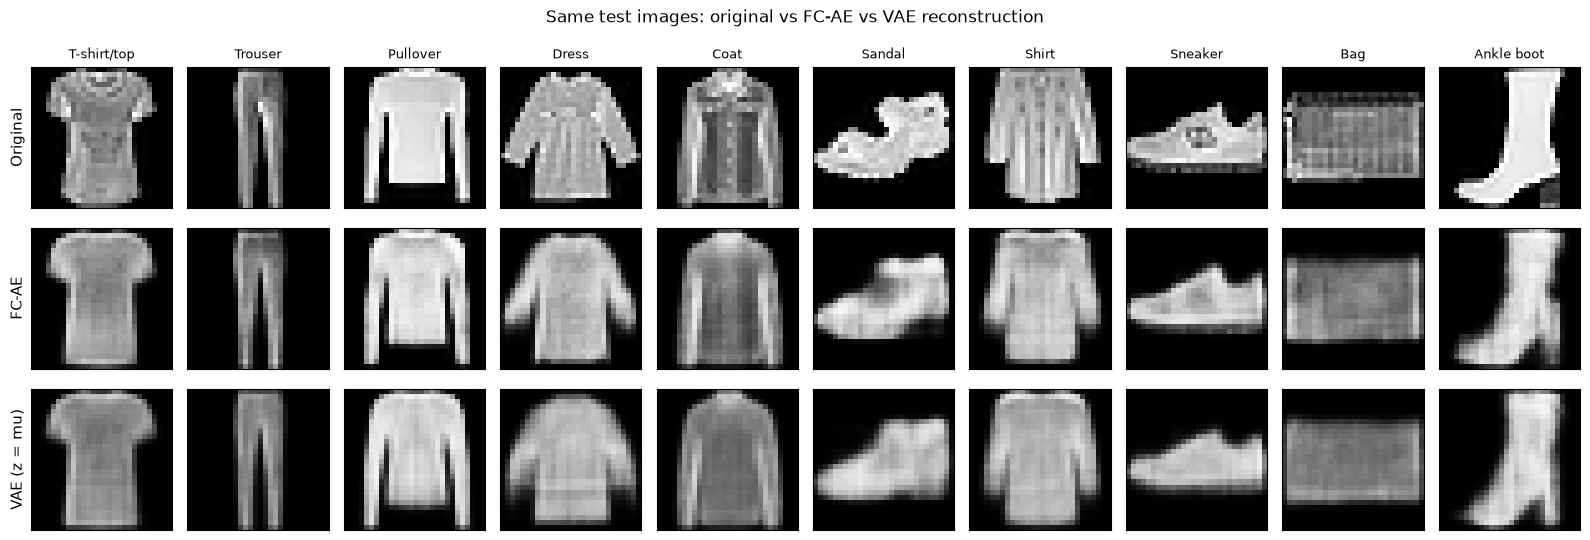

In [17]:
fig, axes = plt.subplots(3, 10, figsize=(16, 5.6))
rows = [("Original", x_display), ("FC-AE", ae_display_recon), ("VAE (z = mu)", vae_display_recon)]
for r, (row_name, imgs) in enumerate(rows):
    for c in range(10):
        ax = axes[r, c]
        ax.imshow(imgs[c].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
        ax.set_xticks([]); ax.set_yticks([])
        if r == 0:
            ax.set_title(y_display[c], fontsize=9)
        if c == 0:
            ax.set_ylabel(row_name, fontsize=11)
plt.suptitle("Same test images: original vs FC-AE vs VAE reconstruction")
plt.tight_layout()
plt.savefig("figures/ae_vs_vae_reconstructions.png", dpi=150)
plt.show()

In [18]:
summary = [
    ("Final train loss (per image)", ae_history["train"][-1], vae_history["train"]["total"][-1]),
    ("Final validation loss (per image)", ae_history["val"][-1], vae_history["val"]["total"][-1]),
    ("Final train reconstruction BCE", ae_history["train"][-1], vae_history["train"]["recon"][-1]),
    ("Final validation reconstruction BCE", ae_history["val"][-1], vae_history["val"]["recon"][-1]),
    ("Final validation KL", float("nan"), vae_history["val"]["kl"][-1]),
    ("Test reconstruction BCE (deterministic)", ae_test["bce_per_image"], vae_test["bce_per_image_mu"]),
    ("Test MSE per pixel (deterministic)", ae_test["mse_per_pixel"], vae_test["mse_per_pixel_mu"]),
    ("Test recon BCE (sampled z, VAE objective)", float("nan"), vae_test["recon_bce_per_image"]),
    ("Test KL (VAE objective)", float("nan"), vae_test["kl_per_image"]),
    ("Test total loss (VAE objective)", ae_test["bce_per_image"], vae_test["total_per_image"]),
]
print(f"{'Metric':<45}{'FC-AE':>14}{'VAE':>14}")
for name, a, v in summary:
    fmt = (lambda val: f"{val:>14.6f}") if "MSE" in name else (lambda val: f"{val:>14.4f}")
    print(f"{name:<45}{('-'.rjust(14) if np.isnan(a) else fmt(a))}{fmt(v)}")

metrics = {
    "personal_parameters": {"SID4": SID4, "SEED": SEED, "SLICE": SLICE, "HP_ID": HP_ID, "CLS_A": CLS_A, "CLS_B": CLS_B},
    "device": device,
    "versions": {"torch": torch.__version__, "torchvision": torchvision.__version__, "numpy": np.__version__},
    "data": {"train": len(train_dataset), "val": len(val_dataset), "test": len(test_dataset),
             "display_indices": DISPLAY_IDX},
    "settings": {"input_dim": INPUT_DIM, "hidden_dim": HIDDEN_DIM, "latent_dim": LATENT_DIM, "batch_size": BATCH_SIZE,
                 "learning_rate": LR, "epochs": EPOCHS, "optimizer": "Adam",
                 "loss_units": "BCE summed over 784 pixels, averaged per image"},
    "parameters": {"fc_ae": count_params(ae), "vae": count_params(vae)},
    "fc_ae": {"history": ae_history, "test": ae_test},
    "vae": {"history": vae_history, "test": vae_test},
    "run_times_seconds": {k: round(v, 1) for k, v in run_times.items()},
}
with open("results/hw7_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

torch.save(ae.state_dict(), f"checkpoints/fc_ae_seed_{SEED}.pt")
torch.save(vae.state_dict(), f"checkpoints/vae_seed_{SEED}.pt")
log("Saved results/hw7_metrics.json, checkpoints/fc_ae_seed_9486.pt, checkpoints/vae_seed_9486.pt | run times (s):",
    metrics["run_times_seconds"])

Metric                                                FC-AE           VAE
Final train loss (per image)                       212.3813      243.0421
Final validation loss (per image)                  212.2384      243.0682
Final train reconstruction BCE                     212.3813      226.9387
Final validation reconstruction BCE                212.2384      226.4851
Final validation KL                                       -       16.5831
Test reconstruction BCE (deterministic)            214.1978      223.7607
Test MSE per pixel (deterministic)                 0.009698      0.013927
Test recon BCE (sampled z, VAE objective)                 -      228.3524
Test KL (VAE objective)                                   -       16.5931
Test total loss (VAE objective)                    214.1978      244.9455
[2026-10-20T05:28:05Z] Saved results/hw7_metrics.json, checkpoints/fc_ae_seed_9486.pt, checkpoints/vae_seed_9486.pt | run times (s): {'fc_ae_training': 114.3, 'vae_training': 120.7}


### Comparing the Two Models

| Metric (per image unless noted) | FC-AE | VAE |
| --- | ---: | ---: |
| Final train loss (FC-AE: BCE; VAE: recon + KL) | 212.38 | 243.04 |
| Final validation loss | 212.24 | 243.07 |
| Final validation reconstruction BCE | 212.24 | 226.49 |
| Final validation KL | – | 16.58 |
| Test reconstruction BCE, deterministic (VAE uses z = mu) | **214.20** | 223.76 |
| Test MSE per pixel, deterministic | **0.009698** | 0.013927 |
| Test VAE objective: recon / KL / total (sampled z) | – | 228.35 / 16.59 / 244.95 |

- **Reconstruction:** the FC-AE is better. Its test BCE is about 9.6 lower per image (214.20 vs 223.76), and its MSE is about 30% lower (0.0097 vs 0.0139). This makes sense, because reconstruction is the FC-AE's only job, while the VAE also pays about 16.6 per image for the KL term. With a sampled z instead of mu, the VAE's reconstruction BCE goes up further to 228.35.
- **Visual quality:** both models get the overall shape of every item right, and both lose fine details like the T-shirt print, the coat's buttons, and the sandal's straps. The FC-AE's outputs are a little sharper. The VAE's are smoother and look more like an "average" item of that class.
- **Generation:** the VAE's 64 prior samples are mostly recognizable but blurry clothing items (T-shirts, pullovers, trousers, boots, sneakers), with a few ambiguous or striped ones. This shows the KL term worked. The FC-AE was not trained to generate, so I did not sample from it.
- **Training:** both models trained smoothly with no overfitting. The VAE's reconstruction term kept dropping (238.36 at epoch 5 to 226.94 at epoch 20), while its KL rose slightly (15.54 to 16.10), meaning the encoder started storing a bit more information in z. The VAE's best validation loss was at epoch 19 (242.86).

**Overall:** the FC-AE is the better compressor, and the VAE is the better generative model.

## Limitations and Observations

- **One seed.** Two full runs gave identical results, but they used the same seed. A different seed or a GPU would change the numbers slightly.
- **Small fully connected models.** Both models are about 0.42M-parameter MLPs that ignore the 2D image structure, which is part of why fine textures get lost. Convolutional models would likely do better.
- **No tuning.** One configuration with 20 epochs, and both models were still improving a little at the end. I did not tune the latent size, the learning rate, or the KL weight.
- **Metrics.** BCE and MSE only measure pixel similarity. They do not measure how realistic the generated samples are (that would need something like FID), so my judgment of the samples is visual.
- **Errors and issues.** No cell raised an error in the final run. The first run's download progress cluttered the output, so I re-ran it once the data was cached. The KL check prints "-0.0000", which is a floating-point negative zero, and the assertion passes.

## Conclusion

GANs train a generator and a discriminator against each other, with the goal that p_g = p_data. Mode collapse is a common failure, which minibatch statistics and WGAN-GP help with. DCGAN, StyleGAN, and Conditional GAN each fix a specific weakness of the vanilla GAN.

For Question 4, the FC-AE reconstructed FashionMNIST better (test BCE 214.20 vs 223.76, MSE 0.0097 vs 0.0139), while the VAE traded some reconstruction quality for the KL term (about 16.6 per image) and in return could generate new, mostly recognizable clothing images from random noise. The main takeaway is the trade-off between exact reconstruction and a smooth latent space you can sample from.